# 02 — Tiền xử lý & Chuẩn hóa dữ liệu (Preprocessing Verification)

Notebook này gọi trực tiếp các hàm dùng chung trong `src/config.py`, `src/data.py` và `src/modeling.py` để:
1. Kiểm chứng bước làm sạch tất định (loại 5 cột thừa/leakage, ép kiểu `HandsetPrice`) và tỷ lệ chia Train/Test (80/20, `stratify=y`).
2. Trực quan hóa dữ liệu thiếu trên tập Train để làm cơ sở cho `SimpleImputer` + `MissingIndicator`.
3. Kiểm tra kích thước ma trận, độ nén `OneHotEncoder(min_frequency=50)` và xác nhận **0 giá trị `NaN` / `Inf`** sau khi đi qua `ColumnTransformer`.
4. Kiểm thử hàm `prepare_raw_input()` với dữ liệu thô đầu vào cho luồng dự đoán thực tế.

> **Nguyên tắc chống Data Leakage:** Việc `fit_transform` trong notebook này chỉ dùng bản `clone()` để kiểm chứng và xuất biểu đồ cho báo cáo. Trong các notebook mô hình (`03`–`06`), `preprocessor` luôn được `fit` riêng bên trong từng training fold của 5-fold Cross-Validation.

## 1. Nạp dữ liệu từ `src/data.py` & Kiểm chứng làm sạch tất định

In [6]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.base import clone
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import RAW_DATA_PATH, PRED_DATA_PATH, FIGURES_DIR, DROP_COLS, ID_COL
from src.data import load_train_test, prepare_raw_input
from src.modeling import build_preprocessor

raw_df = pd.read_csv(RAW_DATA_PATH)
X_train, X_test, y_train, y_test, NUM_COLS, CAT_COLS = load_train_test()

print(f"Dữ liệu gốc          : {raw_df.shape}")
print(f"Các cột loại bỏ ({len(DROP_COLS)})  : {DROP_COLS}")
print(f"Đặc trưng giữ lại    : {X_train.shape[1]} ({len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical)")

split_summary = pd.DataFrame({
    "Tập dữ liệu": ["Train (80%)", "Test (20%)"],
    "Số dòng": [len(X_train), len(X_test)],
    "Số đặc trưng": [X_train.shape[1], X_test.shape[1]],
    "Số mẫu Churn=1": [int(y_train.sum()), int(y_test.sum())],
    "Tỷ lệ Churn (%)": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
})
display(split_summary)

# Minh họa ép kiểu cột HandsetPrice ('Unknown' -> NaN)
unknown_mask = raw_df["HandsetPrice"].astype(str).eq("Unknown")
if unknown_mask.any():
    sample_ids = raw_df.loc[unknown_mask, ID_COL].astype(str).head(5).tolist()
    raw_indexed = raw_df.set_index(raw_df[ID_COL].astype(str))
    combined_hp = pd.concat([X_train["HandsetPrice"], X_test["HandsetPrice"]])
    compare_hp = pd.DataFrame({
        "CustomerID": sample_ids,
        "raw_HandsetPrice": raw_indexed.loc[sample_ids, "HandsetPrice"].values,
        "cleaned_HandsetPrice": combined_hp.loc[sample_ids].values,
    })
    print("\nVí dụ ép kiểu HandsetPrice ('Unknown' -> NaN):")
    display(compare_hp)

Dữ liệu gốc          : (51047, 58)
Các cột loại bỏ (5)  : ['CustomerID', 'Churn', 'RetentionCalls', 'RetentionOffersAccepted', 'MadeCallToRetentionTeam']
Đặc trưng giữ lại    : 53 (33 numeric + 20 categorical)


,Tập dữ liệu,Số dòng,Số đặc trưng,Số mẫu Churn=1,Tỷ lệ Churn (%)
0,Train (80%),40837,53,11769,28.82
1,Test (20%),10210,53,2942,28.81



Ví dụ ép kiểu HandsetPrice ('Unknown' -> NaN):


,CustomerID,raw_HandsetPrice,cleaned_HandsetPrice
0,3000014,Unknown,NaN
1,3000174,Unknown,NaN
2,3000230,Unknown,NaN
3,3000238,Unknown,NaN
4,3000290,Unknown,NaN


## 2. Trực quan hóa dữ liệu thiếu (Missing Values) trên tập Train

Tổng số cột có giá trị thiếu trên Train: 15 / 53


,missing_pct (%)
HandsetPrice,56.85
AgeHH1,1.75
AgeHH2,1.75
PercChangeRevenues,0.71
PercChangeMinutes,0.71
OverageMinutes,0.29
DirectorAssistedCalls,0.29
RoamingCalls,0.29
MonthlyRevenue,0.29
MonthlyMinutes,0.29


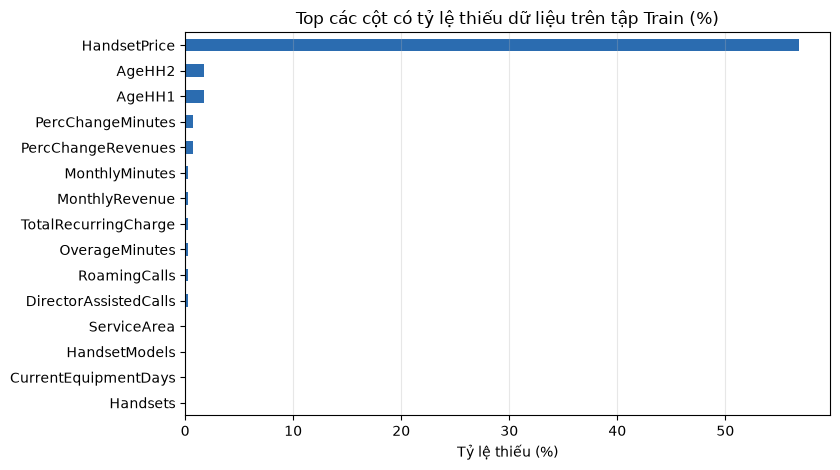

Đã lưu biểu đồ: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\figures\02_missing_values_train.png


In [7]:
missing_pct = (X_train.isna().mean() * 100).sort_values(ascending=False)
top_missing = missing_pct[missing_pct > 0].head(15)

print(f"Tổng số cột có giá trị thiếu trên Train: {(missing_pct > 0).sum()} / {X_train.shape[1]}")
display(top_missing.to_frame("missing_pct (%)").round(2))

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
top_missing.sort_values().plot(kind="barh", ax=ax, color="#2b6cb0")
ax.set_title("Top các cột có tỷ lệ thiếu dữ liệu trên tập Train (%)")
ax.set_xlabel("Tỷ lệ thiếu (%)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_missing_values_train.png", dpi=150)
plt.show()
print("Đã lưu biểu đồ:", FIGURES_DIR / "02_missing_values_train.png")

## 3. Kiểm chứng `build_preprocessor()` từ `src/modeling.py`
Kiểm tra cấu trúc ma trận đầu ra, số lượng cờ `MissingIndicator`, số cột `OneHotEncoder` và xác nhận không còn `NaN`/`Inf` trên cả Train lẫn Test (chỉ `fit` trên Train).

In [8]:
preprocessor = build_preprocessor(NUM_COLS, CAT_COLS, min_frequency=50)
prep_demo = clone(preprocessor)

Z_train = prep_demo.fit_transform(X_train)
Z_test = prep_demo.transform(X_test)

def count_nan_inf(mat):
    data = mat.data if sparse.issparse(mat) else np.asarray(mat)
    return int(np.isnan(data).sum()), int(np.isinf(data).sum())

tr_nan, tr_inf = count_nan_inf(Z_train)
te_nan, te_inf = count_nan_inf(Z_test)

num_union = prep_demo.named_transformers_["num"]
miss_idx = dict(num_union.transformer_list)["missing_ind"].features_
miss_cols = [NUM_COLS[i] for i in miss_idx]

ohe = prep_demo.named_transformers_["cat"].named_steps["encoder"]
cat_out_names = ohe.get_feature_names_out(CAT_COLS).tolist()

print(f"Ma trận Z_train: {Z_train.shape} | sparse={sparse.issparse(Z_train)} | NaN={tr_nan} | Inf={tr_inf}")
print(f"Ma trận Z_test : {Z_test.shape} | sparse={sparse.issparse(Z_test)} | NaN={te_nan} | Inf={te_inf}")
print("-" * 60)
print(f"  1) Đặc trưng số đã StandardScaler : {len(NUM_COLS)} cột")
print(f"  2) Cờ báo thiếu MissingIndicator  : {len(miss_cols)} cột -> {miss_cols[:8]}")
print(f"  3) Đặc trưng phân loại One-Hot    : {len(cat_out_names)} cột")
print(f"  => Tổng cộng                      : {len(NUM_COLS) + len(miss_cols) + len(cat_out_names)} cột")

Ma trận Z_train: (40837, 284) | sparse=True | NaN=0 | Inf=0
Ma trận Z_test : (10210, 284) | sparse=True | NaN=0 | Inf=0
------------------------------------------------------------
  1) Đặc trưng số đã StandardScaler : 33 cột
  2) Cờ báo thiếu MissingIndicator  : 14 cột -> ['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues']
  3) Đặc trưng phân loại One-Hot    : 237 cột
  => Tổng cộng                      : 284 cột


## 4. Độ nén của `OneHotEncoder(min_frequency=50)` & Kiểm tra `StandardScaler`

In [9]:
# 4.1 Bảng đối chiếu độ nén các cột phân loại nhiều danh mục (như ServiceArea)
cat_summary = pd.DataFrame([
    {
        "column": col,
        "raw_unique_incl_missing": int(X_train[col].fillna("Missing").nunique()),
        "ohe_output_cols": sum(1 for name in cat_out_names if name.startswith(f"{col}_")),
    }
    for col in CAT_COLS
]).sort_values("raw_unique_incl_missing", ascending=False).reset_index(drop=True)

print("Top 10 cột phân loại theo số lượng danh mục gốc vs sau OneHotEncoder(min_frequency=50):")
display(cat_summary.head(10))

# 4.2 Kiểm tra nhanh phân phối sau StandardScaler (mean ~ 0, std ~ 1) trên 5 cột số đầu
Z_tr_dense = Z_train[:, :len(NUM_COLS)].toarray() if sparse.issparse(Z_train) else Z_train[:, :len(NUM_COLS)]
scale_check = pd.DataFrame({
    "feature": NUM_COLS[:5],
    "raw_mean": [X_train[c].mean() for c in NUM_COLS[:5]],
    "raw_std": [X_train[c].std() for c in NUM_COLS[:5]],
    "scaled_mean": [Z_tr_dense[:, i].mean() for i in range(5)],
    "scaled_std": [Z_tr_dense[:, i].std() for i in range(5)],
}).round(4)

print("\nKiểm tra StandardScaler trên 5 đặc trưng số đầu tiên (Train):")
display(scale_check)

Top 10 cột phân loại theo số lượng danh mục gốc vs sau OneHotEncoder(min_frequency=50):


,column,raw_unique_incl_missing,ohe_output_cols
0,ServiceArea,730,185
1,Occupation,8,8
2,CreditRating,7,7
3,PrizmCode,4,4
4,MaritalStatus,3,3
5,HandsetWebCapable,2,2
6,ChildrenInHH,2,2
7,HandsetRefurbished,2,2
8,TruckOwner,2,2
9,RVOwner,2,2



Kiểm tra StandardScaler trên 5 đặc trưng số đầu tiên (Train):


,feature,raw_mean,raw_std,scaled_mean,scaled_std
0,MonthlyRevenue,58.9921,44.9538,0.0,1.0
1,MonthlyMinutes,525.2429,528.3980,0.0,1.0
2,TotalRecurringCharge,46.8590,23.8542,0.0,1.0
3,DirectorAssistedCalls,0.8977,2.2465,0.0,1.0
4,OverageMinutes,40.3113,97.9211,-0.0,1.0


## 5. Kiểm thử `prepare_raw_input()` cho luồng dự đoán dữ liệu mới
Đảm bảo dữ liệu thô tải lên (như `Telecom - Prediction Data.csv`) đi qua `prepare_raw_input()` và `preprocessor.transform()` không bị lỗi cột lạ hay sai kiểu dữ liệu.

In [10]:
if PRED_DATA_PATH.exists():
    sample_raw = pd.read_csv(PRED_DATA_PATH).head(10)
    source_name = PRED_DATA_PATH.name
else:
    sample_raw = raw_df.head(10).copy()
    source_name = RAW_DATA_PATH.name

X_new = prepare_raw_input(sample_raw, NUM_COLS, CAT_COLS)
Z_new = prep_demo.transform(X_new)
new_nan, new_inf = count_nan_inf(Z_new)

print(f"Nguồn kiểm thử        : {source_name} ({sample_raw.shape})")
print(f"Sau prepare_raw_input : {X_new.shape} | Còn cột drop? {[c for c in DROP_COLS if c in X_new.columns]}")
print(f"Sau transform         : {Z_new.shape} | NaN={new_nan} | Inf={new_inf}")

Nguồn kiểm thử        : Telecom - Prediction Data.csv ((10, 58))
Sau prepare_raw_input : (10, 53) | Còn cột drop? []
Sau transform         : (10, 284) | NaN=0 | Inf=0
